# CDC Diabetes Risk Prediction - Model Pipeline & Evaluation


In [57]:
import pandas as pd

In [58]:
train_df = pd.read_csv('train.csv')
predict_df = pd.read_csv('test.csv')

In [59]:
train_df

,id,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,diabetes_risk
0,3,0,0,1,24,0,0,0,0,1,...,1,2,5,10,1,0,13,4,5,0
1,4,0,0,1,24,1,0,0,1,1,...,0,2,0,0,0,1,3,4,8,0
2,5,1,1,1,32,1,1,0,0,0,...,0,1,0,15,1,1,10,4,5,0
3,6,1,1,1,32,0,0,1,0,0,...,0,3,3,25,1,1,12,5,4,1
4,7,0,0,1,36,1,0,0,0,1,...,0,1,0,0,0,1,10,6,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202938,253670,1,0,1,26,0,0,0,0,1,...,0,2,10,0,0,0,11,5,6,0
202939,253672,1,1,1,23,1,0,0,0,0,...,0,3,2,2,0,1,9,4,6,0
202940,253677,0,0,1,20,0,0,0,0,0,...,0,2,0,7,0,0,7,5,8,0
202941,253679,0,0,1,25,0,0,0,1,1,...,0,1,0,0,0,1,3,6,8,0


In [60]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202943 entries, 0 to 202942
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   id                    202943 non-null  int64
 1   HighBP                202943 non-null  int64
 2   HighChol              202943 non-null  int64
 3   CholCheck             202943 non-null  int64
 4   BMI                   202943 non-null  int64
 5   Smoker                202943 non-null  int64
 6   Stroke                202943 non-null  int64
 7   HeartDiseaseorAttack  202943 non-null  int64
 8   PhysActivity          202943 non-null  int64
 9   Fruits                202943 non-null  int64
 10  Veggies               202943 non-null  int64
 11  HvyAlcoholConsump     202943 non-null  int64
 12  AnyHealthcare         202943 non-null  int64
 13  NoDocbcCost           202943 non-null  int64
 14  GenHlth               202943 non-null  int64
 15  MentHlth              202943 non-n

In [61]:
predict_df

,id,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,0,1,1,24,1,0,0,1,0,...,1,0,5,1,30,1,0,13,4,2
1,2,1,1,1,27,0,0,0,1,1,...,1,0,2,0,0,0,1,7,6,8
2,11,0,1,1,27,0,0,0,1,0,...,1,0,2,0,0,0,1,8,6,8
3,19,0,1,1,20,1,0,1,0,1,...,1,0,5,15,25,1,0,7,4,1
4,36,0,0,1,30,1,0,0,1,0,...,1,0,3,0,5,1,0,7,2,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50732,253673,0,0,1,22,0,0,0,1,1,...,1,0,1,0,30,0,0,9,6,8
50733,253674,0,0,0,32,1,0,0,1,1,...,1,0,3,0,0,0,1,7,4,7
50734,253675,0,1,1,36,0,0,0,0,1,...,1,0,3,2,2,0,1,1,6,7
50735,253676,0,0,1,25,0,0,0,1,1,...,1,0,3,4,0,0,0,4,5,8


In [62]:
predict_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50737 entries, 0 to 50736
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   id                    50737 non-null  int64
 1   HighBP                50737 non-null  int64
 2   HighChol              50737 non-null  int64
 3   CholCheck             50737 non-null  int64
 4   BMI                   50737 non-null  int64
 5   Smoker                50737 non-null  int64
 6   Stroke                50737 non-null  int64
 7   HeartDiseaseorAttack  50737 non-null  int64
 8   PhysActivity          50737 non-null  int64
 9   Fruits                50737 non-null  int64
 10  Veggies               50737 non-null  int64
 11  HvyAlcoholConsump     50737 non-null  int64
 12  AnyHealthcare         50737 non-null  int64
 13  NoDocbcCost           50737 non-null  int64
 14  GenHlth               50737 non-null  int64
 15  MentHlth              50737 non-null  int64
 16  Phys

In [63]:
X = train_df.drop(columns=['id', 'diabetes_risk'])
y = train_df['diabetes_risk']

In [64]:
predict_ids = predict_df['id']
X_pre = predict_df.drop(columns=['id'])

In [65]:
class_counts = y.value_counts()
class_percentages = y.value_counts(normalize=True) * 100
print(class_counts)
print(class_percentages)

diabetes_risk
0    170962
1     31981
Name: count, dtype: int64
diabetes_risk
0    84.241388
1    15.758612
Name: proportion, dtype: float64


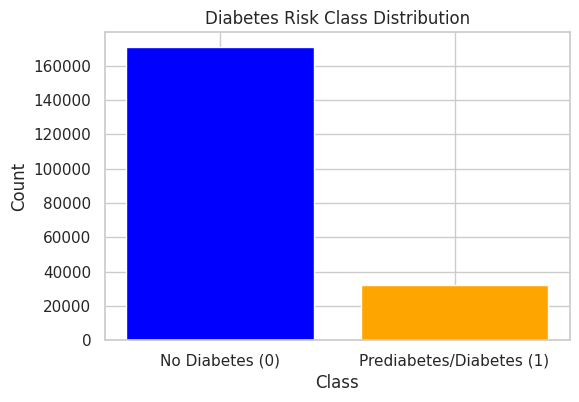

In [66]:
import matplotlib.pyplot as plt
class_counts = y.value_counts()

plt.figure(figsize=(6, 4))
plt.bar(['No Diabetes (0)', 'Prediabetes/Diabetes (1)'], class_counts, color=['blue', 'orange'])

plt.title('Diabetes Risk Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

plt.show()

### Observation: Class Imbalance in Diabetes Risk Distribution
* The dataset exhibits a significant class imbalance, with the majority of instances belonging to the "No Diabetes (0)" class (blue bar, approx. 170k+ samples).
* The minority class "Prediabetes/Diabetes (1)" (orange bar, approx. 30k+ samples) is substantially smaller.
* This imbalance justifies the use of stratified splitting and the ROC-AUC evaluation metric, as standard accuracy would be misleading for an imbalanced classification task.



In [67]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [68]:

correlations = X.corrwith(y).sort_values(ascending=False)

print(correlations)

GenHlth                 0.301236
HighBP                  0.270814
BMI                     0.223843
DiffWalk                0.223295
HighChol                0.210256
Age                     0.186470
HeartDiseaseorAttack    0.178946
PhysHlth                0.174238
Stroke                  0.105309
MentHlth                0.074670
CholCheck               0.068581
Smoker                  0.063309
NoDocbcCost             0.038770
Sex                     0.029562
AnyHealthcare           0.012887
Fruits                 -0.038880
HvyAlcoholConsump      -0.057074
Veggies                -0.057874
PhysActivity           -0.120862
Education              -0.132777
Income                 -0.172170
dtype: float64


In [69]:
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

def evaluate_models(X_tr, X_te, y_tr, y_te):
    models = {
        "LightGBM": lgb.LGBMClassifier(random_state=42, verbosity=-1),
        "CatBoost": CatBoostClassifier(random_state=42, verbose=0),
        "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
        "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100)
    }

    results = []

    for name, model in models.items():
        model.fit(X_tr, y_tr)
        preds = model.predict_proba(X_te)[:, 1]
        score = roc_auc_score(y_te, preds)
        results.append({"Model Name": name, "Validation ROC-AUC Score": score})

    return pd.DataFrame(results)

model_comparison_df = evaluate_models(X_train, X_test, y_train, y_test)

In [70]:
model_comparison_df.sort_values(by="Validation ROC-AUC Score", ascending=False).reset_index(drop=True)

,Model Name,Validation ROC-AUC Score
0,LightGBM,0.829615
1,CatBoost,0.827959
2,XGBoost,0.825018
3,Random Forest,0.798259


### Observation: Model Performance Comparison
* **LightGBM** achieved the highest ROC-AUC score, outperforming CatBoost, XGBoost, and Random Forest.
* Gradient boosting frameworks consistently demonstrate superior predictive capability on tabular health data compared to bagging estimators.

In [73]:
final_model = lgb.LGBMClassifier(random_state=42, verbosity=-1)
final_model.fit(X, y)

final_preds = final_model.predict_proba(X_pre)[:, 1]

submission = pd.DataFrame({
    'id': predict_ids,
    'prediction': final_preds
})

submission.to_csv('submission.csv', index=False)